In [97]:
import pandas as pd
import numpy as np
import os
import textwrap
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.ticker import MaxNLocator

In [98]:
df = pd.read_parquet("../data/cleaned_data.parquet")

In [99]:
df["pickup_zone"].value_counts()
pick_up_zone_count = df.groupby("pickup_zone").agg(
   count = ("order_id","count")
).reset_index()
pick_up_zone_count

,pickup_zone,count
0,cbd,10997
1,commercial,9523
2,industrial,7233
3,residential,15786
4,suburban,6461


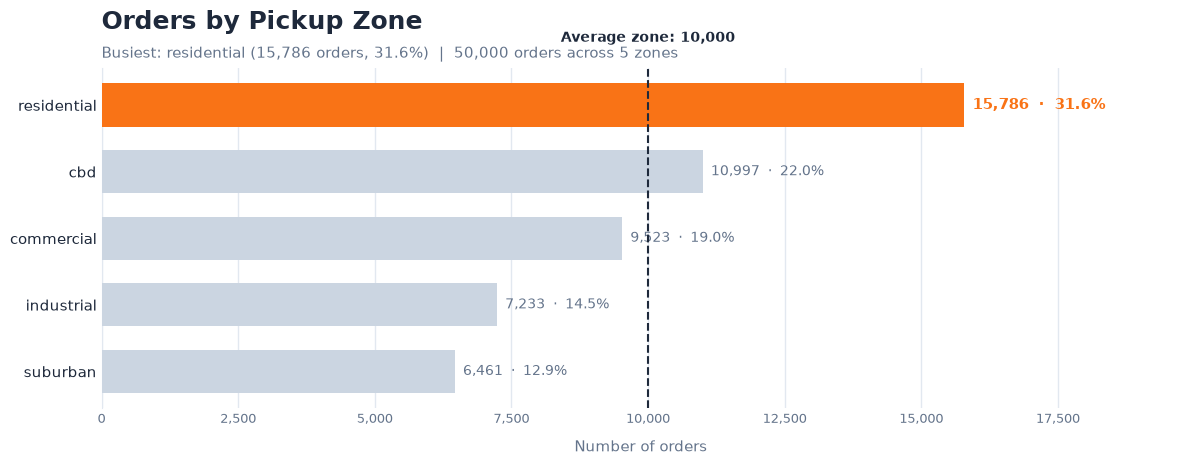

In [100]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

TOP_N = 15   # max zones to show

# ---------------- Prep ----------------
data = (pick_up_zone_count.sort_values("count", ascending=False)
        .head(TOP_N).reset_index(drop=True))
labels = data["pickup_zone"].astype(str).apply(lambda s: textwrap.fill(s, 28))
counts = data["count"]

total_all = int(pick_up_zone_count["count"].sum())
shares    = counts / total_all * 100
avg       = pick_up_zone_count["count"].mean()
top_zone  = data["pickup_zone"].iloc[0]

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(12, max(4.5, len(data) * 0.55 + 2)))
fig.patch.set_facecolor("white")

colors = [PEAK if i == 0 else BASE for i in range(len(data))]
bars = ax.barh(labels, counts, color=colors, height=0.65, zorder=3)
ax.invert_yaxis()   # busiest at the top

# Labels: order count and share of all orders
t = ax.bar_label(bars,
                 labels=[f"{c:,.0f}  ·  {s:.1f}%" for c, s in zip(counts, shares)],
                 padding=6, fontsize=10, color=MUTED)
t[0].set_color(PEAK)
t[0].set_fontweight("bold")
t[0].set_fontsize(11)

# Average reference line
ax.axvline(avg, color=TEXT, linestyle="--", linewidth=1.5, zorder=4)
ax.text(avg, -0.9, f"Average zone: {avg:,.0f}", ha="center", va="bottom",
        fontsize=10, color=TEXT, fontweight="bold")

# Titles
ax.set_title("Orders by Pickup Zone", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Busiest: {top_zone} ({counts.iloc[0]:,.0f} orders, {shares.iloc[0]:.1f}%)  |  "
        f"{total_all:,} orders across {len(pick_up_zone_count)} zones",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
ax.set_xlabel("Number of orders", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("")
ax.set_xlim(0, counts.max() * 1.25)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.tick_params(axis="y", labelsize=11, colors=TEXT, length=0)
ax.tick_params(axis="x", labelsize=9, colors=MUTED, length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="x", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color(GRID)

plt.tight_layout()

plt.savefig("../images/orders_by_pickup_zone.png", dpi=180)
plt.show()

In [101]:
# How long does preparation take on average, and how much of total delivery
#      time is waiting for food?
avg_prep_time = df["preparation_time_min"].mean().round()
prep_time_max = df["preparation_time_min"].max()
prep_time_min = df["preparation_time_min"].min() 
print(f"The average prep time is {avg_prep_time} min")
print(f"The range is between {prep_time_min} - {prep_time_max} min")

# how much of total delivery time is waiting for food?
tot_del_time_wai_food = df["waiting_pct"].mean().round(2)
print(f"The average percent of delivery time spent on waiting for food is {tot_del_time_wai_food}")

The average prep time is 24.0 min
The range is between 5 - 51 min
The average percent of delivery time spent on waiting for food is 32.64


In [102]:
# Which cuisines are slowest and fastest to deliver?
# Which cuisines have the longest preparation times?
cuisine_prep_time = df.groupby(["cuisine_type"]).agg(
    num_of_orders = ("order_id","count"),
    avg_prep_time = ("preparation_time_min","mean"),
    avg_del_time = ("time_taken_min","mean")
).reset_index().round().sort_values(by="avg_prep_time",ascending=False)
cuisine_prep_time

,cuisine_type,num_of_orders,avg_prep_time,avg_del_time
1,biryani,7802,34.0,94.0
6,north indian,9483,30.0,90.0
7,pizza,6661,26.0,87.0
4,chinese,6132,24.0,85.0
8,south indian,5109,22.0,81.0
2,burger,5198,17.0,74.0
3,cafe,4035,15.0,74.0
0,bakery,2908,13.0,74.0
5,desserts,2672,13.0,76.0


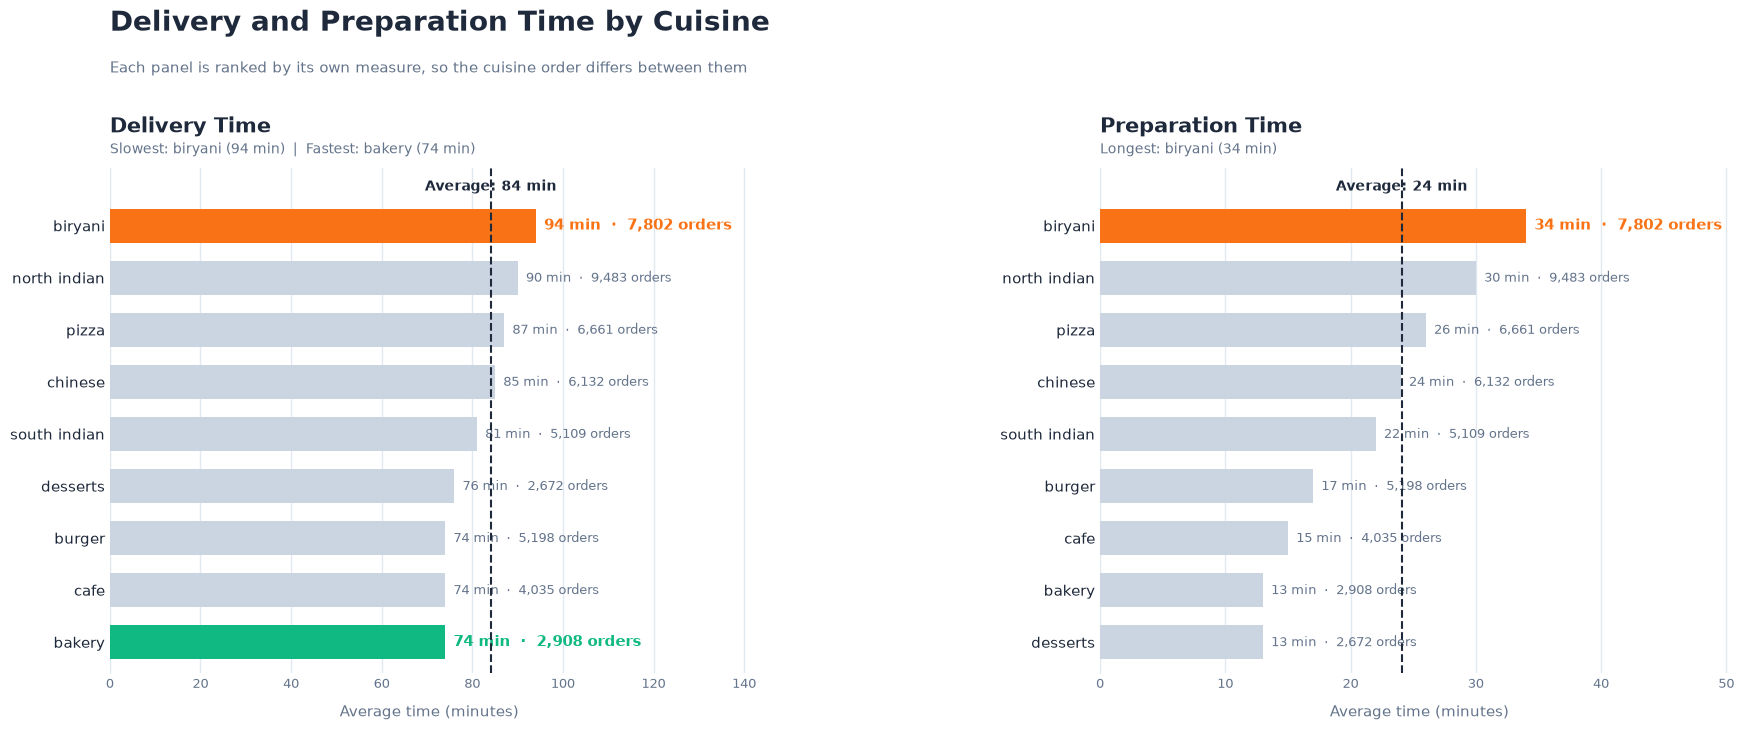

In [117]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
GOOD  = "#10B981"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

TOP_N = 15   # max cuisines to show per panel

def cuisine_panel(ax, col, title, kicker, show_fastest=False):
    """Horizontal bars, longest at the top. Longest = orange, fastest = green (optional)."""
    d = (cuisine_prep_time.sort_values(col, ascending=False)
         .head(TOP_N).reset_index(drop=True))
    n = len(d)
    labels = d["cuisine_type"].astype(str).apply(lambda s: textwrap.fill(s, 22))
    vals, orders = d[col], d["num_of_orders"]

    # Average across all orders (weighted by how many orders each cuisine has)
    avg = (cuisine_prep_time[col] * cuisine_prep_time["num_of_orders"]).sum() \
          / cuisine_prep_time["num_of_orders"].sum()

    last = n - 1
    colors = [BASE] * n
    colors[0] = PEAK
    if show_fastest and last > 0:
        colors[last] = GOOD

    y = np.arange(n)
    bars = ax.barh(y, vals, color=colors, height=0.65, zorder=3)

    t = ax.bar_label(bars,
                     labels=[f"{v:.0f} min  ·  {c:,} orders" for v, c in zip(vals, orders)],
                     padding=6, fontsize=9.5, color=MUTED)
    t[0].set_color(PEAK); t[0].set_fontweight("bold"); t[0].set_fontsize(10.5)
    if show_fastest and last > 0:
        t[last].set_color(GOOD); t[last].set_fontweight("bold"); t[last].set_fontsize(10.5)

    # Average reference line
    ax.axvline(avg, color=TEXT, linestyle="--", linewidth=1.5, zorder=4)
    ax.text(avg, -0.75, f"Average: {avg:.0f} min", ha="center", va="center",
            fontsize=10, color=TEXT, fontweight="bold")

    # Titles
    short = lambda s: textwrap.shorten(str(s), 18, placeholder="…")
    sub = f"{kicker}: {short(d['cuisine_type'].iloc[0])} ({vals.iloc[0]:.0f} min)"
    if show_fastest and last > 0:
        sub += f"  |  Fastest: {short(d['cuisine_type'].iloc[last])} ({vals.iloc[last]:.0f} min)"
    ax.set_title(title, loc="left", fontsize=15, fontweight="bold", color=TEXT, pad=26)
    ax.text(0, 1.03, sub, transform=ax.transAxes, fontsize=10, color=MUTED)

    # Axes
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=10.5, color=TEXT)
    ax.set_ylim(n - 0.4, -1.1)   # longest at the top, room above for the average label
    ax.set_xlim(0, vals.max() * 1.5)
    ax.set_xlabel("Average time (minutes)", fontsize=11, color=MUTED, labelpad=10)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", labelsize=9, colors=MUTED, length=0)

    # Clean look
    ax.set_axisbelow(True)
    ax.grid(axis="x", color=GRID, linewidth=1, zorder=0)
    for side in ["top", "right", "bottom"]:
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(GRID)

# ---------------- Figure ----------------
n_rows = min(TOP_N, len(cuisine_prep_time))
H = max(5.5, n_rows * 0.55 + 3)
fig, axes = plt.subplots(1, 2, figsize=(18, H))
fig.patch.set_facecolor("white")
fig.subplots_adjust(left=0.08, right=0.985, top=1 - 2.0 / H, bottom=0.9 / H, wspace=0.55)

# 1. Which cuisines are slowest and fastest to deliver?
cuisine_panel(axes[0], "avg_del_time", "Delivery Time", "Slowest", show_fastest=True)

# 2. Which cuisines have the longest preparation times?
cuisine_panel(axes[1], "avg_prep_time", "Preparation Time", "Longest")

# Main title
fig.text(0.08, 1 - 0.55 / H, "Delivery and Preparation Time by Cuisine", fontsize=20,
         fontweight="bold", color=TEXT, va="center")
fig.text(0.08, 1 - 1.0 / H,
         "Each panel is ranked by its own measure, so the cuisine order differs between them",
         fontsize=11, color=MUTED, va="center")


plt.savefig("../images/cuisine_delivery_and_prep_time.png", dpi=180, facecolor="white")
plt.show()

In [104]:
# Does a higher restaurant rating mean faster preparation or delivery?
corr_bet_rating_deltime = df["restaurant_rating"].corr(df["time_taken_min"])
corr_bet_rating_deltime

np.float64(0.018994041469844455)

In [105]:
rating_corr_prep_time = df.groupby("restaurant_rating").agg(
    avg_prep_time = ("preparation_time_min","mean"),
    avg_del_time = ("time_taken_min","mean")
).reset_index().round(2).sort_values("avg_del_time",ascending=False)
rating_corr_prep_time

,restaurant_rating,avg_prep_time,avg_del_time
17,5.0,34.49,98.07
16,4.9,23.51,87.29
15,4.8,26.85,86.48
3,3.6,25.02,86.15
12,4.5,25.30,85.34
14,4.7,24.06,85.00
6,3.9,25.81,84.97
5,3.8,22.23,84.96
10,4.3,23.74,83.91
2,3.5,25.17,83.78


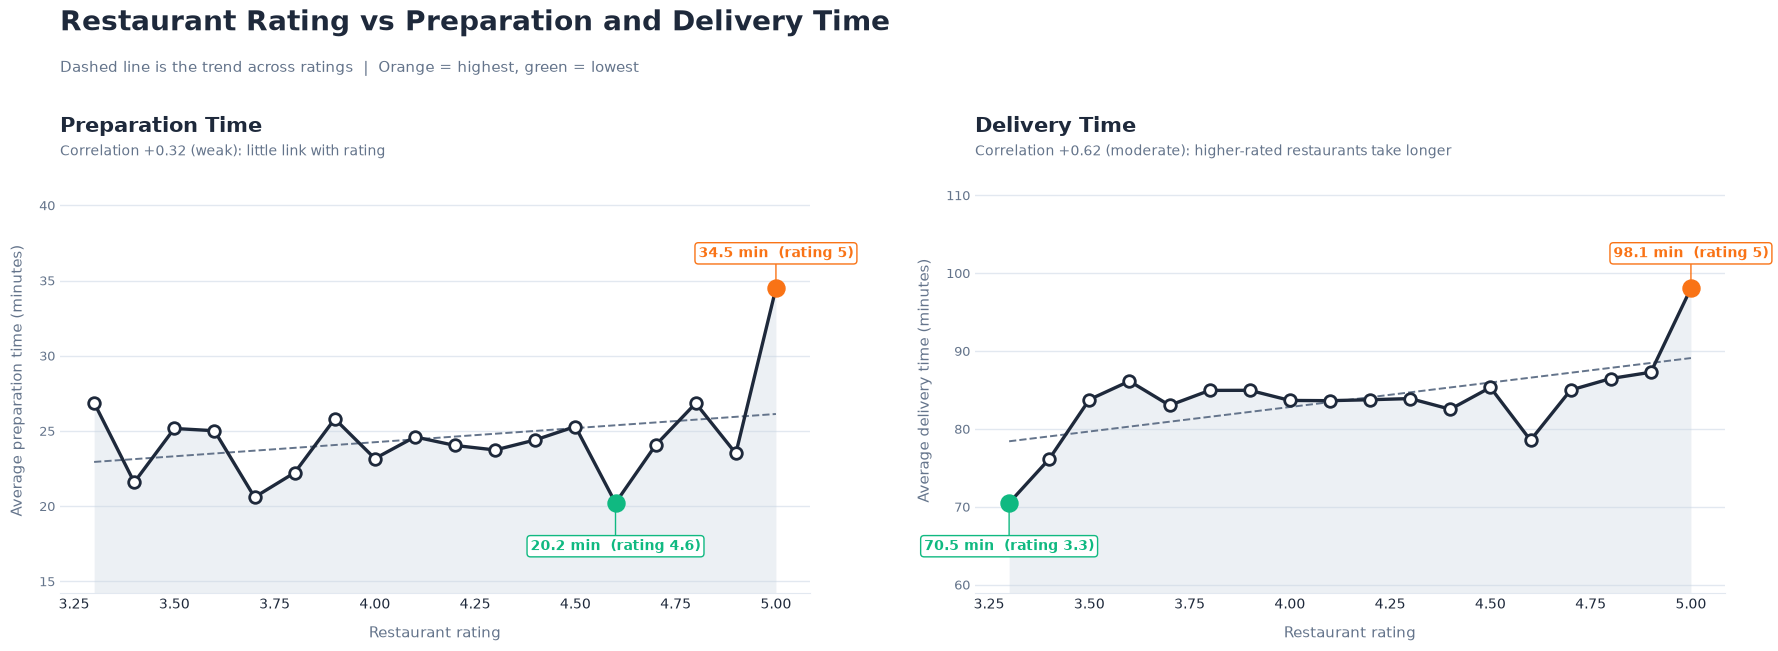

In [118]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
GOOD  = "#10B981"
LINE  = "#1E293B"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

def rating_panel(ax, col, title, ylabel):
    d = rating_corr_prep_time.sort_values("restaurant_rating").reset_index(drop=True)
    x = d["restaurant_rating"].astype(float)
    y = d[col].astype(float)

    hi, lo = int(y.values.argmax()), int(y.values.argmin())

    # Trend line + correlation across ratings
    slope, intercept = np.polyfit(x, y, 1)
    corr = np.corrcoef(x, y)[0, 1]
    strength = "strong" if abs(corr) >= 0.7 else "moderate" if abs(corr) >= 0.4 else "weak"
    if abs(corr) < 0.4:
        meaning = "little link with rating"
    elif corr > 0:
        meaning = "higher-rated restaurants take longer"
    else:
        meaning = "higher-rated restaurants are faster"

    # Zoom into the real range (extra headroom for the labels)
    pad  = (y.max() - y.min()) * 0.35 or 1
    y_lo = y.min() - pad * 1.2
    y_hi = y.max() + pad * 1.6
    ax.set_ylim(y_lo, y_hi)

    # Grey area, trend line, then the data line and points
    ax.fill_between(x, y, y_lo, color=BASE, alpha=0.35, linewidth=0, zorder=1)
    ax.plot(x, slope * x + intercept, color=MUTED, linestyle="--", linewidth=1.4, zorder=2)
    ax.plot(x, y, color=LINE, linewidth=2.4, zorder=3)
    ax.scatter(x, y, s=70, color="white", edgecolor=LINE, linewidth=2, zorder=4)
    ax.scatter(x.iloc[hi], y.iloc[hi], s=150, color=PEAK, zorder=5)
    ax.scatter(x.iloc[lo], y.iloc[lo], s=150, color=GOOD, zorder=5)

    # Labels on the highest and lowest points
    ax.annotate(f"{y.iloc[hi]:.1f} min  (rating {x.iloc[hi]:g})", (x.iloc[hi], y.iloc[hi]),
                xytext=(0, 20), textcoords="offset points", ha="center", va="bottom",
                fontsize=10, fontweight="bold", color=PEAK, zorder=6,
                bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=PEAK, linewidth=1),
                arrowprops=dict(arrowstyle="-", color=PEAK, linewidth=1, shrinkA=0, shrinkB=6))
    ax.annotate(f"{y.iloc[lo]:.1f} min  (rating {x.iloc[lo]:g})", (x.iloc[lo], y.iloc[lo]),
                xytext=(0, -26), textcoords="offset points", ha="center", va="top",
                fontsize=10, fontweight="bold", color=GOOD, zorder=6,
                bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=GOOD, linewidth=1),
                arrowprops=dict(arrowstyle="-", color=GOOD, linewidth=1, shrinkA=0, shrinkB=6))

    # Panel title
    ax.set_title(title, loc="left", fontsize=15, fontweight="bold", color=TEXT, pad=26)
    ax.text(0, 1.03, f"Correlation {corr:+.2f} ({strength}): {meaning}",
            transform=ax.transAxes, fontsize=10, color=MUTED)

    # Axes
    xpad = (x.max() - x.min()) * 0.05 or 0.1
    ax.set_xlim(x.min() - xpad, x.max() + xpad)
    if len(x) <= 12:
        ax.set_xticks(x)
        ax.set_xticklabels([f"{v:g}" for v in x], fontsize=10, color=TEXT)
    else:
        ax.tick_params(axis="x", labelsize=10, colors=TEXT)
    ax.set_xlabel("Restaurant rating", fontsize=11, color=MUTED, labelpad=10)
    ax.set_ylabel(ylabel, fontsize=11, color=MUTED, labelpad=10)
    ax.yaxis.set_major_locator(MaxNLocator(6))
    ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)
    ax.tick_params(axis="x", length=0)

    # Clean look
    ax.set_axisbelow(True)
    ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

# ---------------- Figure ----------------
H = 7.2
fig, axes = plt.subplots(1, 2, figsize=(18, H))
fig.patch.set_facecolor("white")
fig.subplots_adjust(left=0.06, right=0.985, top=1 - 2.0 / H, bottom=0.95 / H, wspace=0.22)

# 1. Does restaurant rating relate to preparation time?
rating_panel(axes[0], "avg_prep_time", "Preparation Time",
             "Average preparation time (minutes)")

# 2. Does restaurant rating relate to delivery time?
rating_panel(axes[1], "avg_del_time", "Delivery Time",
             "Average delivery time (minutes)")

# Main title
fig.text(0.06, 1 - 0.55 / H, "Restaurant Rating vs Preparation and Delivery Time",
         fontsize=20, fontweight="bold", color=TEXT, va="center")
fig.text(0.06, 1 - 1.0 / H,
         "Dashed line is the trend across ratings  |  Orange = highest, green = lowest",
         fontsize=11, color=MUTED, va="center")


plt.savefig("../images/rating_vs_prep_and_delivery_time.png", dpi=180, facecolor="white")
plt.show()

In [121]:
# Do larger orders (more items) take longer to prepare?
rerutant_load_prep_time = df.groupby(["restaurant_load"]).agg(
    avg_del_time = ("time_taken_min","median"),
    avg_prep_time = ("preparation_time_min","median")
).reset_index().round()
rerutant_load_prep_time

,restaurant_load,avg_del_time,avg_prep_time
0,high,80.0,27.0
1,low,76.0,23.0
2,medium,78.0,24.0


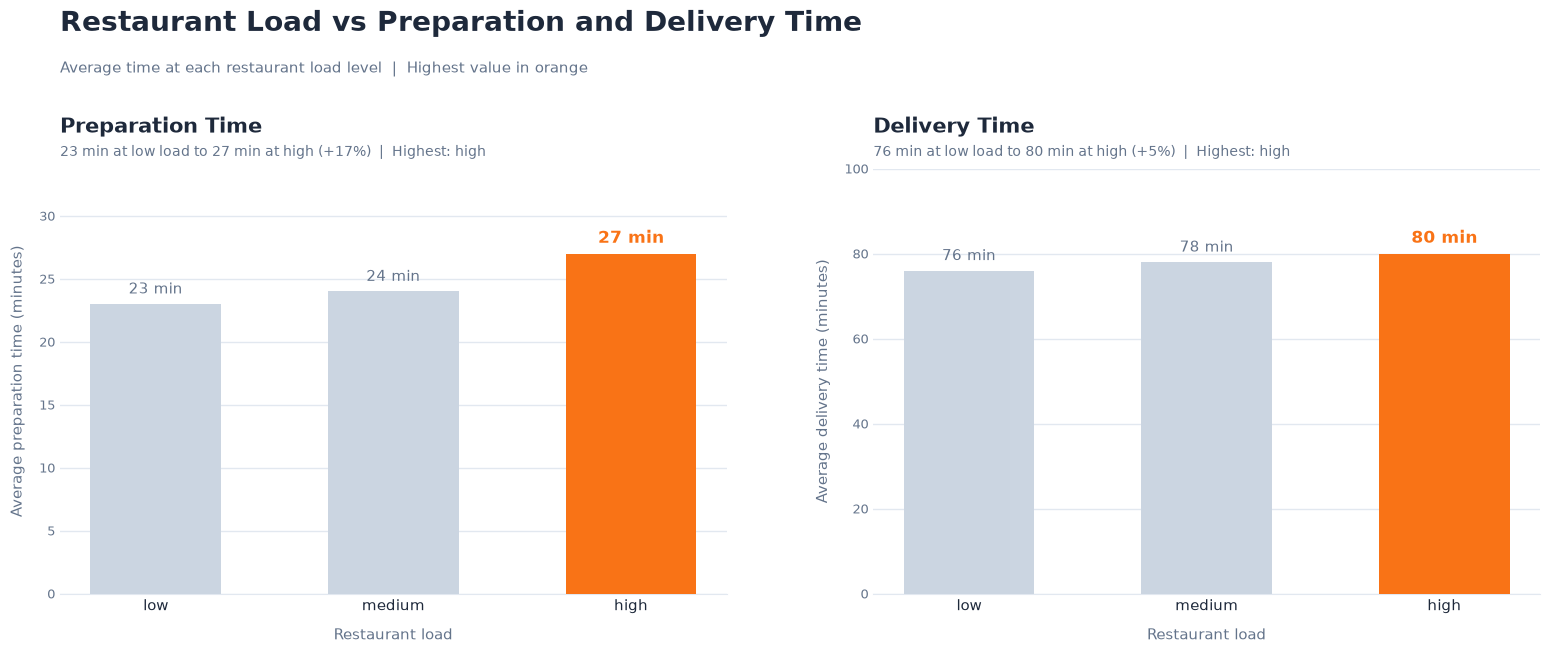

In [122]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

# Natural order for text labels (extend if yours differ)
RANK = {"very low": 0, "low": 1, "light": 1, "medium": 2, "moderate": 2, "normal": 2,
        "high": 3, "heavy": 3, "very high": 4, "peak": 4, "extreme": 4}

def order_load(d):
    """Return (data in natural load order, whether a natural order was found)."""
    lab = d["restaurant_load"]
    if pd.api.types.is_numeric_dtype(lab):
        return d.sort_values("restaurant_load"), True
    key = lab.astype(str).str.strip().str.lower().map(RANK)
    if key.notna().all():
        return d.assign(_k=key).sort_values("_k").drop(columns="_k"), True
    nums = lab.astype(str).str.extract(r"(\d+)")[0]
    if nums.notna().all():
        return d.assign(_k=nums.astype(int)).sort_values("_k").drop(columns="_k"), True
    return d, False

def load_panel(ax, col, title, ylabel):
    d, ordered = order_load(rerutant_load_prep_time.copy())
    d = d.reset_index(drop=True)
    labels = d["restaurant_load"].astype(str)
    vals = d[col].astype(float)
    hi = int(vals.values.argmax())

    colors = [PEAK if i == hi else BASE for i in range(len(d))]
    bars = ax.bar(labels, vals, color=colors, width=0.55, zorder=3)
    t = ax.bar_label(bars, labels=[f"{v:.0f} min" for v in vals], padding=5,
                     fontsize=11, color=MUTED)
    t[hi].set_color(PEAK); t[hi].set_fontweight("bold"); t[hi].set_fontsize(12)

    # Panel title
    if ordered and len(d) > 1:
        change = (vals.iloc[-1] - vals.iloc[0]) / vals.iloc[0] * 100
        sub = (f"{vals.iloc[0]:.0f} min at {labels.iloc[0]} load to {vals.iloc[-1]:.0f} min "
               f"at {labels.iloc[-1]} ({change:+.0f}%)  |  Highest: {labels.iloc[hi]}")
    else:
        sub = f"Highest: {labels.iloc[hi]} ({vals.iloc[hi]:.0f} min)"
    ax.set_title(title, loc="left", fontsize=15, fontweight="bold", color=TEXT, pad=26)
    ax.text(0, 1.03, sub, transform=ax.transAxes, fontsize=10, color=MUTED)

    # Axes
    ax.set_xlabel("Restaurant load", fontsize=11, color=MUTED, labelpad=10)
    ax.set_ylabel(ylabel, fontsize=11, color=MUTED, labelpad=10)
    ax.set_ylim(0, vals.max() * 1.25)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.tick_params(axis="x", labelsize=11, colors=TEXT, length=0)
    ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)

    # Clean look
    ax.set_axisbelow(True)
    ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

# ---------------- Figure ----------------
H = 7.2
fig, axes = plt.subplots(1, 2, figsize=(16, H))
fig.patch.set_facecolor("white")
fig.subplots_adjust(left=0.06, right=0.985, top=1 - 2.0 / H, bottom=0.95 / H, wspace=0.22)

# 1. Does a heavier restaurant load mean longer preparation?
load_panel(axes[0], "avg_prep_time", "Preparation Time",
           "Average preparation time (minutes)")

# 2. Does it also slow delivery?
load_panel(axes[1], "avg_del_time", "Delivery Time",
           "Average delivery time (minutes)")

# Main title
fig.text(0.06, 1 - 0.55 / H, "Restaurant Load vs Preparation and Delivery Time",
         fontsize=20, fontweight="bold", color=TEXT, va="center")
fig.text(0.06, 1 - 1.0 / H,
         "Average time at each restaurant load level  |  Highest value in orange",
         fontsize=11, color=MUTED, va="center")


plt.savefig("../images/restaurant_load_vs_prep_and_delivery_time.png", dpi=180, facecolor="white")
plt.show()

In [109]:
corr_resturant_load_time_taken = df["order_items"].corr(df["time_taken_min"])
corr_resturant_load_time_taken

np.float64(0.08160264677214496)

In [110]:
# Do larger orders (more items) take longer to prepare?
order_item_prep_time = df.groupby(["order_items"]).agg(
    avg_del_time = ("time_taken_min","mean"),
    avg_prep_time = ("preparation_time_min","mean")
).reset_index().round()
order_item_prep_time

,order_items,avg_del_time,avg_prep_time
0,1,81.0,21.0
1,2,83.0,23.0
2,3,84.0,25.0
3,4,86.0,27.0
4,5,88.0,29.0
5,6,89.0,31.0
6,7,93.0,33.0


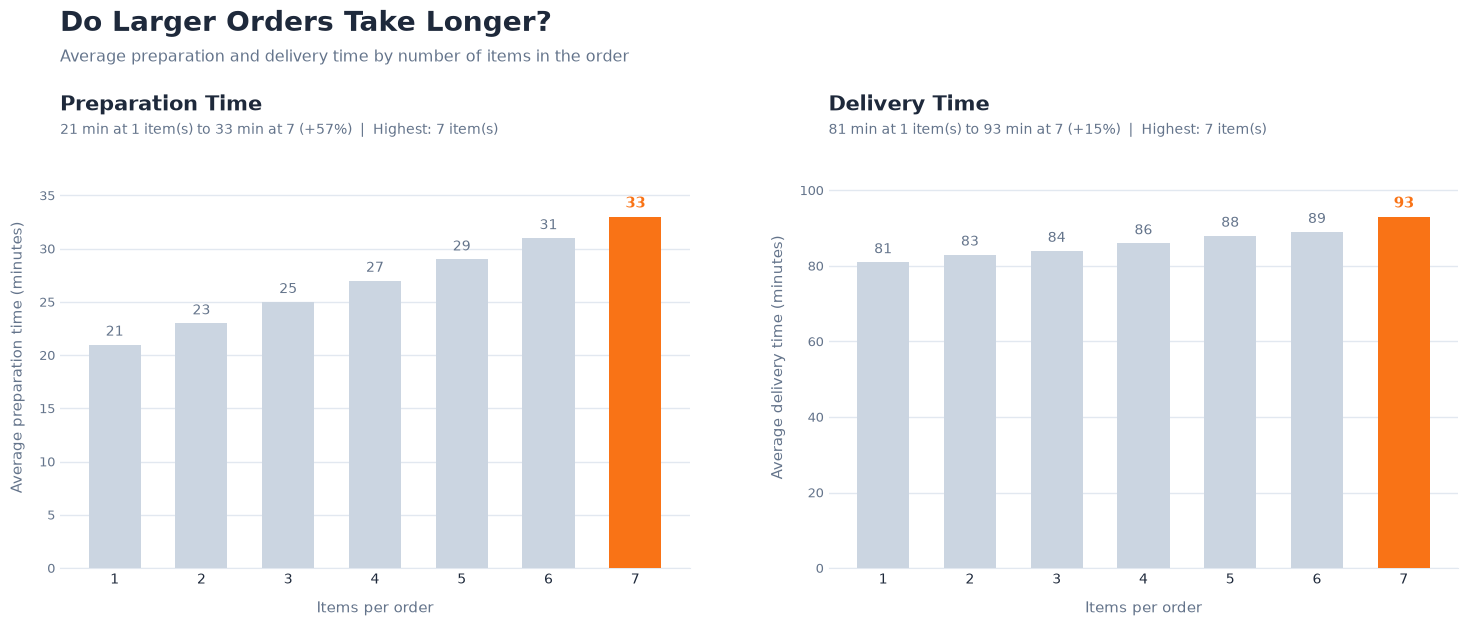

In [115]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

# ---------------- Prep ----------------
data = order_item_prep_time.sort_values("order_items").reset_index(drop=True)
items = data["order_items"].astype(int).astype(str)
n = len(data)

panels = [
    ("avg_prep_time", "Preparation Time", "Average preparation time (minutes)"),
    ("avg_del_time",  "Delivery Time",    "Average delivery time (minutes)"),
]

# ---------------- Plot ----------------
fig, axes = plt.subplots(1, 2, figsize=(max(14, n * 1.6 + 4), 6.8))
fig.patch.set_facecolor("white")
fig.subplots_adjust(left=0.06, right=0.98, top=0.76, bottom=0.14, wspace=0.22)

for ax, (col, title, ylabel) in zip(axes, panels):
    vals = data[col].astype(float)
    hi = int(vals.values.argmax())
    change = (vals.iloc[-1] - vals.iloc[0]) / vals.iloc[0] * 100 if n > 1 else 0

    colors = [PEAK if i == hi else BASE for i in range(n)]
    bars = ax.bar(items, vals, color=colors, width=0.6, zorder=3)
    t = ax.bar_label(bars, labels=[f"{v:.0f}" for v in vals], padding=4,
                     fontsize=10 if n <= 10 else 8.5, color=MUTED)
    t[hi].set_color(PEAK)
    t[hi].set_fontweight("bold")
    t[hi].set_fontsize(11 if n <= 10 else 9.5)

    ax.set_title(title, loc="left", fontsize=15, fontweight="bold", color=TEXT, pad=26)
    ax.text(0, 1.03,
            f"{vals.iloc[0]:.0f} min at {items.iloc[0]} item(s) to "
            f"{vals.iloc[-1]:.0f} min at {items.iloc[-1]} ({change:+.0f}%)  |  "
            f"Highest: {items.iloc[hi]} item(s)",
            transform=ax.transAxes, fontsize=10, color=MUTED)

    ax.set_xlabel("Items per order", fontsize=11, color=MUTED, labelpad=10)
    ax.set_ylabel(ylabel, fontsize=11, color=MUTED, labelpad=10)
    ax.set_ylim(0, vals.max() * 1.2)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.tick_params(axis="x", labelsize=10, colors=TEXT, length=0)
    ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)

    ax.set_axisbelow(True)
    ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

# Main title
fig.text(0.06, 0.93, "Do Larger Orders Take Longer?", fontsize=20, fontweight="bold", color=TEXT)
fig.text(0.06, 0.885, "Average preparation and delivery time by number of items in the order",
         fontsize=11.5, color=MUTED)

os.makedirs("../images", exist_ok=True)
plt.savefig("../images/order_items_vs_time.png", dpi=180, facecolor="white")
plt.show()

In [111]:
pick = df.groupby("pickup_zone").agg(
    prep_time = ("preparation_time_min","mean")
).reset_index().round()
pick

,pickup_zone,prep_time
0,cbd,26.0
1,commercial,23.0
2,industrial,22.0
3,residential,23.0
4,suburban,25.0


In [112]:
# Define slow preparation using the 75th percentile
threshold = df["preparation_time_min"].quantile(0.75)

# Identify slow orders
df["is_slow"] = df["preparation_time_min"] > threshold

# Analyze slow orders by pickup zone
slow_zones = df.groupby("pickup_zone").agg(
    total_orders=("is_slow", "size"),
    slow_orders=("is_slow", "sum")
)

# Percentage of orders in each zone that are slow
slow_zones["slow_order_pct_in_zone"] = (
    slow_zones["slow_orders"] / slow_zones["total_orders"] * 100
)

# Percentage of all slow orders contributed by each zone
slow_zones["pct_of_all_slow_orders"] = (
    slow_zones["slow_orders"] / slow_zones["slow_orders"].sum() * 100
)

slow_zones = slow_zones.sort_values(
    "slow_order_pct_in_zone", ascending=False
).reset_index().round(2)

slow_zones

,pickup_zone,total_orders,slow_orders,slow_order_pct_in_zone,pct_of_all_slow_orders
0,cbd,10997,3561,32.38,29.96
1,residential,15786,3601,22.81,30.30
2,suburban,6461,1435,22.21,12.07
3,commercial,9523,2004,21.04,16.86
4,industrial,7233,1284,17.75,10.80


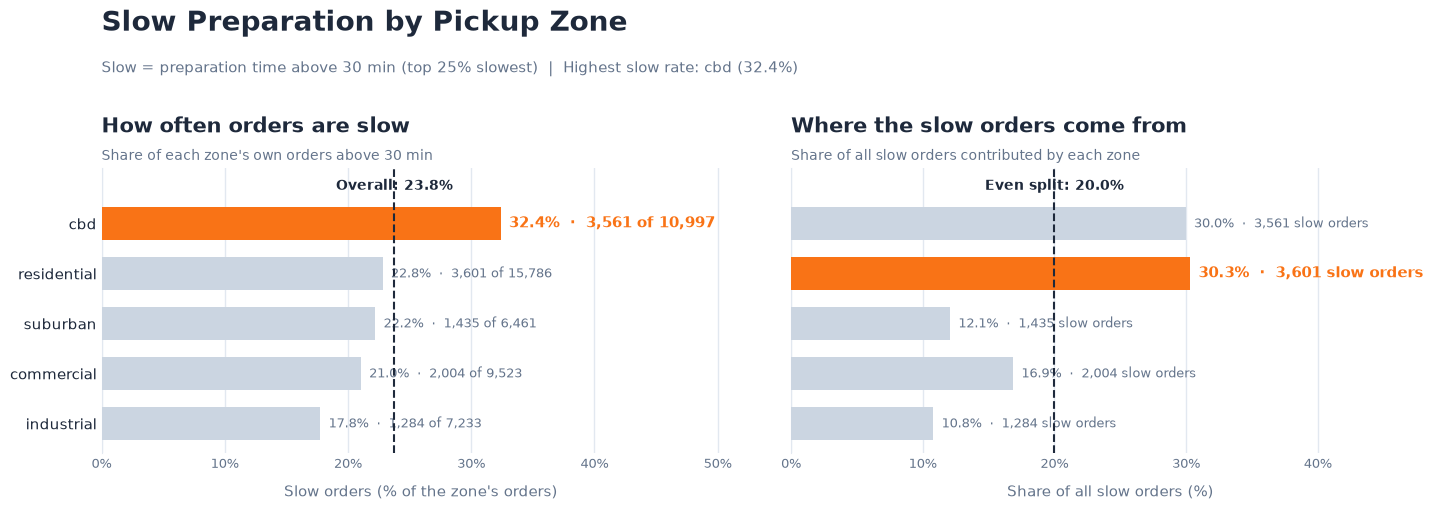

In [116]:
# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

TOP_N = 15   # max zones to show (ranked by slow-order rate)

# ---------------- Prep ----------------
data = (slow_zones.sort_values("slow_order_pct_in_zone", ascending=False)
        .head(TOP_N).reset_index(drop=True))
n = len(data)
labels = data["pickup_zone"].astype(str).apply(lambda s: textwrap.fill(s, 26))

overall_rate = slow_zones["slow_orders"].sum() / slow_zones["total_orders"].sum() * 100
even_share   = 100 / len(slow_zones)
thr_txt = f"{threshold:.0f} min" if "threshold" in globals() else "the 75th percentile"

panels = [
    dict(col="slow_order_pct_in_zone", title="How often orders are slow",
         sub=f"Share of each zone's own orders above {thr_txt}",
         ref=overall_rate, ref_txt=f"Overall: {overall_rate:.1f}%",
         xlabel="Slow orders (% of the zone's orders)",
         lab=lambda r: f"{r['slow_order_pct_in_zone']:.1f}%  ·  "
                       f"{int(r['slow_orders']):,} of {int(r['total_orders']):,}"),
    dict(col="pct_of_all_slow_orders", title="Where the slow orders come from",
         sub="Share of all slow orders contributed by each zone",
         ref=even_share, ref_txt=f"Even split: {even_share:.1f}%",
         xlabel="Share of all slow orders (%)",
         lab=lambda r: f"{r['pct_of_all_slow_orders']:.1f}%  ·  "
                       f"{int(r['slow_orders']):,} slow orders"),
]

# ---------------- Plot ----------------
H = max(5.5, n * 0.55 + 3)
fig, axes = plt.subplots(1, 2, figsize=(16, H), sharey=True)
fig.patch.set_facecolor("white")
fig.subplots_adjust(left=0.15, right=0.98, top=1 - 2.0 / H, bottom=0.9 / H, wspace=0.08)

y = np.arange(n)
for ax, p in zip(axes, panels):
    vals = data[p["col"]]
    hi = int(vals.values.argmax())

    colors = [PEAK if i == hi else BASE for i in range(n)]
    bars = ax.barh(y, vals, color=colors, height=0.65, zorder=3)
    t = ax.bar_label(bars, labels=[p["lab"](r) for _, r in data.iterrows()],
                     padding=6, fontsize=9.5, color=MUTED)
    t[hi].set_color(PEAK); t[hi].set_fontweight("bold"); t[hi].set_fontsize(10.5)

    # Benchmark line
    ax.axvline(p["ref"], color=TEXT, linestyle="--", linewidth=1.5, zorder=4)
    ax.text(p["ref"], -0.75, p["ref_txt"], ha="center", va="center",
            fontsize=10, color=TEXT, fontweight="bold")

    ax.set_title(p["title"], loc="left", fontsize=15, fontweight="bold", color=TEXT, pad=26)
    ax.text(0, 1.03, p["sub"], transform=ax.transAxes, fontsize=10, color=MUTED)

    ax.set_xlim(0, max(vals.max(), p["ref"]) * 1.6)
    ax.set_ylim(n - 0.4, -1.1)   # top row first, room above for the benchmark label
    ax.set_xlabel(p["xlabel"], fontsize=11, color=MUTED, labelpad=10)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
    ax.tick_params(axis="x", labelsize=9, colors=MUTED, length=0)
    ax.tick_params(axis="y", length=0)

    ax.set_axisbelow(True)
    ax.grid(axis="x", color=GRID, linewidth=1, zorder=0)
    for side in ["top", "right", "bottom"]:
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(GRID)

axes[0].set_yticks(y)
axes[0].set_yticklabels(labels, fontsize=11, color=TEXT)
axes[1].tick_params(labelleft=False)

# Main title
top_zone = data["pickup_zone"].iloc[0]
fig.text(0.15, 1 - 0.55 / H, "Slow Preparation by Pickup Zone", fontsize=20,
         fontweight="bold", color=TEXT, va="center")
fig.text(0.15, 1 - 1.0 / H,
         f"Slow = preparation time above {thr_txt} (top 25% slowest)  |  "
         f"Highest slow rate: {top_zone} ({data['slow_order_pct_in_zone'].iloc[0]:.1f}%)",
         fontsize=11, color=MUTED, va="center")


plt.savefig("../images/slow_prep_by_zone.png", dpi=180, facecolor="white")
plt.show()

In [113]:
high_resturant_load = df.groupby("order_hour").agg(
    load_volume = ("order_items","sum")
).reset_index().sort_values("load_volume",ascending=False)
high_resturant_load

,order_hour,load_volume
19,19,12659
13,13,10282
18,18,10205
20,20,10117
12,12,9140
8,8,6545
7,7,6502
17,17,6449
11,11,6326
21,21,6311


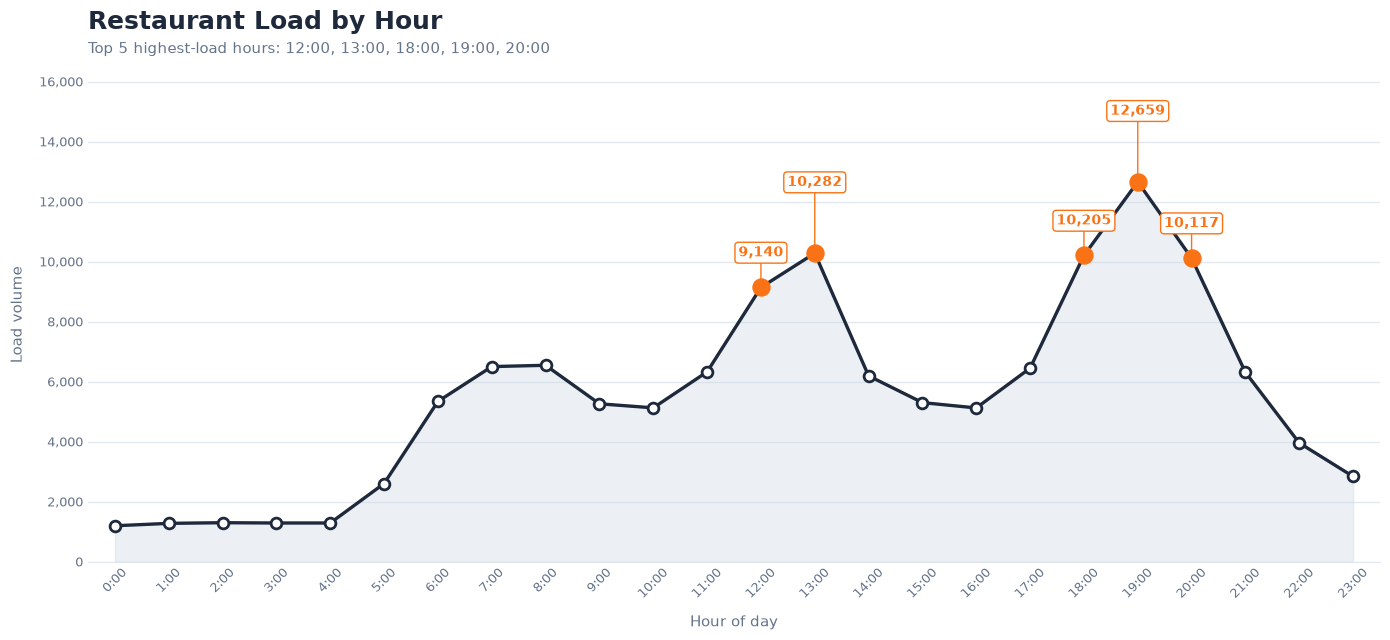

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
LINE  = "#1E293B"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

N_PEAK = 5   # how many highest-load hours to highlight

data   = high_resturant_load.sort_values("order_hour").reset_index(drop=True)
hours  = data["order_hour"]
load   = data["load_volume"]

thr     = load.nlargest(N_PEAK).min()
is_peak = (load >= thr).values

fig, ax = plt.subplots(figsize=(14, 6.5))
fig.patch.set_facecolor("white")

# Area + line + points
ax.fill_between(hours, load, color=BASE, alpha=0.35, zorder=1)
ax.plot(hours, load, color=LINE, linewidth=2.4, zorder=3)
ax.scatter(hours[~is_peak], load[~is_peak], s=60, color="white",
           edgecolor=LINE, linewidth=2, zorder=4)
ax.scatter(hours[is_peak], load[is_peak], s=150, color=PEAK, zorder=5)

# Labels on peak hours: stagger consecutive hours so they never touch
pill = dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=PEAK, linewidth=1)
level, prev_h = 0, None
for h, v, p in zip(hours, load, is_peak):
    if not p:
        continue
    level = level + 1 if (prev_h is not None and h - prev_h == 1) else 0
    prev_h = h
    up = 20 + (level % 2) * 26
    ax.annotate(f"{v:,.0f}", (h, v), xytext=(0, up), textcoords="offset points",
                ha="center", va="bottom", fontsize=10, fontweight="bold",
                color=PEAK, bbox=pill, zorder=6,
                arrowprops=dict(arrowstyle="-", color=PEAK, linewidth=1,
                                shrinkA=0, shrinkB=6))

# Titles
peak_hours = ", ".join(f"{h}:00" for h in hours[is_peak])
ax.set_title("Restaurant Load by Hour", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03, f"Top {N_PEAK} highest-load hours: {peak_hours}",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes (starts at 0 because of the area fill)
ax.set_ylim(0, load.max() * 1.3)
ax.set_xlim(hours.min() - 0.5, hours.max() + 0.5)
ax.set_xticks(np.arange(0, 24))
ax.set_xticklabels([f"{h}:00" for h in range(24)], rotation=45, fontsize=9, color=MUTED)
ax.set_xlabel("Hour of day", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Load volume", fontsize=11, color=MUTED, labelpad=10)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.tick_params(axis="y", labelsize=9, colors=MUTED, length=0)
ax.tick_params(axis="x", length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.tight_layout()

plt.savefig("../images/restaurant_load_by_hour.png")
plt.show()